In [9]:

import pandas as pd

df = pd.read_csv("housing.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (20640, 10)
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [10]:
# Display all column names
print("All columns in dataset:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Display dataset information
print("\nDataset information:")
df.info()

All columns in dataset:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Missing values in each column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate rows: 0

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population       

In [11]:
# Display all column names
print("All columns in dataset:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Display dataset information
print("\nDataset information:")
df.info()

All columns in dataset:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Missing values in each column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate rows: 0

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population       

In [12]:
# Target column: the value we want to predict
TARGET = "median_house_value"

if TARGET not in df.columns:
    print("Target column not found. Check the column names above.")
else:
    print("Target column found:", TARGET)
    print("\nHouse value statistics:")
    print(df[TARGET].describe())
    

Target column found: median_house_value

House value statistics:
count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64


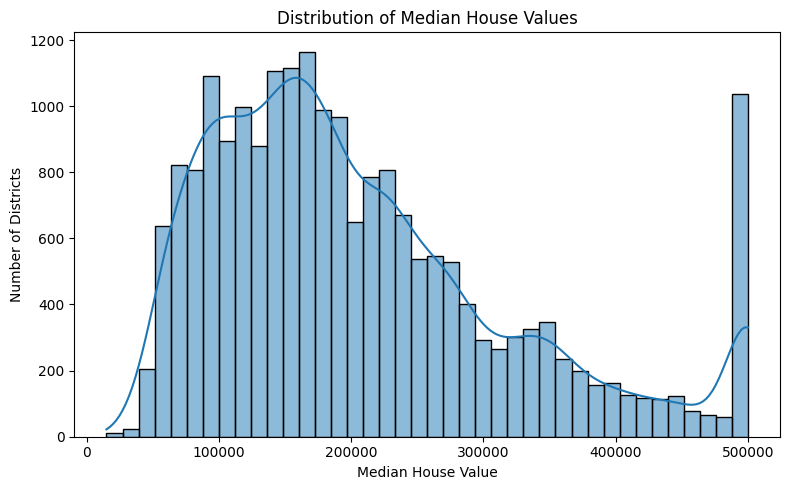

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x=TARGET,
    bins=40,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Number of Districts")
plt.tight_layout()
plt.show()

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Target column
TARGET = "median_house_value"

# Separate input features and target
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Split data before fitting preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Preprocessing pipelines
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Data preparation setup completed!")


Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']

Training rows: 16512
Testing rows: 4128
Data preparation setup completed!


In [17]:
import numpy as np
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Each model gets the same preprocessing steps
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", Ridge())
    ]),

    "Lasso Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", Lasso(max_iter=20000))
    ])
}

trained_models = {}
predictions = {}
results = []

for name, pipeline in models.items():
    if name == "Ridge Regression":
        params = {"model__alpha": [0.1, 1, 10, 100]}
    elif name == "Lasso Regression":
        params = {"model__alpha": [0.001, 0.01, 0.1, 1]}
    else:
        params = None

    if params:
        search = GridSearchCV(
            pipeline,
            params,
            cv=5,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1
        )
        search.fit(X_train, y_train)
        fitted_model = search.best_estimator_
        print(name, "best parameters:", search.best_params_)
    else:
        fitted_model = pipeline.fit(X_train, y_train)

    y_pred = fitted_model.predict(X_test)

    trained_models[name] = fitted_model
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")

print("\nModel Performance Comparison:")
display(results_df.round(2))

Ridge Regression best parameters: {'model__alpha': 1}
Lasso Regression best parameters: {'model__alpha': 0.1}

Model Performance Comparison:


C:\Users\Pratiksha\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.300e+12, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


,Model,MAE,RMSE,R2 Score
0,Linear Regression,50670.49,70059.19,0.63
2,Lasso Regression,50670.59,70059.28,0.63
1,Ridge Regression,50676.92,70066.02,0.63


In [18]:
import matplotlib.pyplot as plt
from pathlib import Path

# Select model with lowest RMSE
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
y_pred = predictions[best_model_name]

print("Best model:", best_model_name)
print("RMSE:", round(results_df.iloc[0]["RMSE"], 2))
print("R2 Score:", round(results_df.iloc[0]["R2 Score"], 4))

Path("outputs").mkdir(exist_ok=True)

Best model: Linear Regression
RMSE: 70059.19
R2 Score: 0.6254


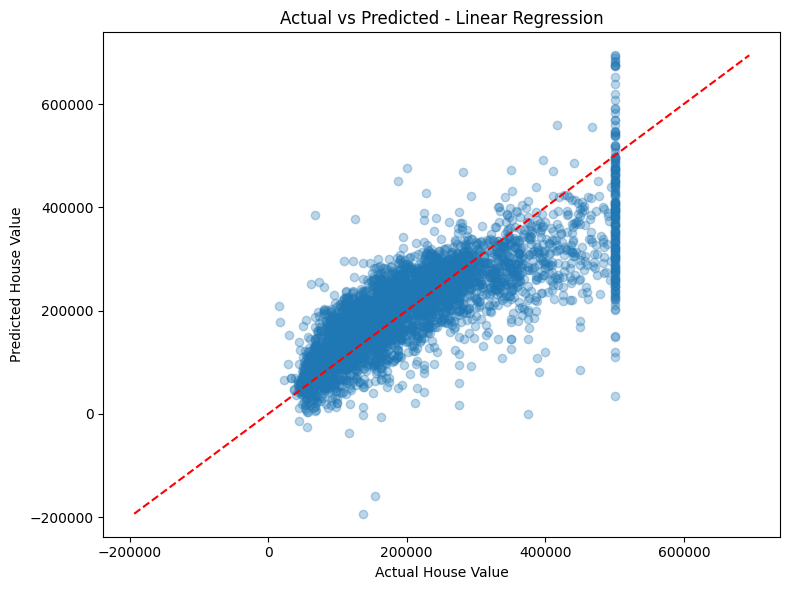

In [19]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title(f"Actual vs Predicted - {best_model_name}")

plt.tight_layout()
plt.savefig("outputs/actual_vs_predicted.png", dpi=150)
plt.show()

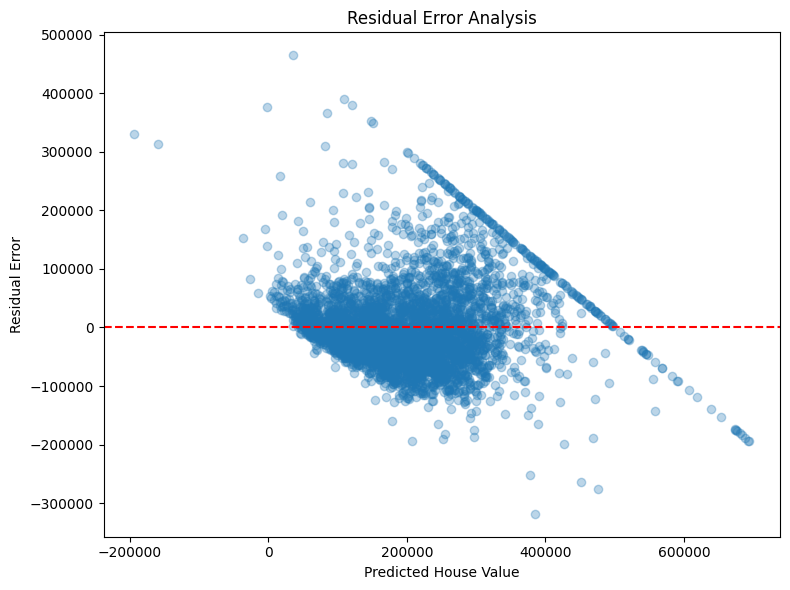

In [20]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Value")
plt.ylabel("Residual Error")
plt.title("Residual Error Analysis")

plt.tight_layout()
plt.savefig("outputs/residual_plot.png", dpi=150)
plt.show()

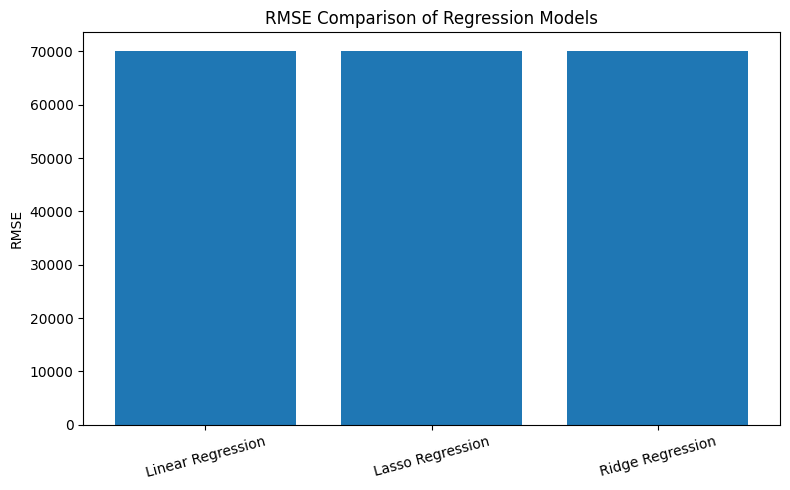

In [21]:
plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["RMSE"])

plt.ylabel("RMSE")
plt.title("RMSE Comparison of Regression Models")
plt.xticks(rotation=15)

plt.tight_layout()
plt.savefig("outputs/model_comparison.png", dpi=150)
plt.show()

In [22]:
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=100000, tol=0.001))
])

lasso_search = GridSearchCV(
    lasso_pipeline,
    {"model__alpha": [0.01, 0.1, 1, 10]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

print("Best Lasso parameters:", lasso_search.best_params_)

lasso_pred = lasso_search.best_estimator_.predict(X_test)

print("Lasso MAE:", round(mean_absolute_error(y_test, lasso_pred), 2))
print("Lasso RMSE:", round(np.sqrt(mean_squared_error(y_test, lasso_pred)), 2))
print("Lasso R2:", round(r2_score(y_test, lasso_pred), 4))

Best Lasso parameters: {'model__alpha': 0.1}
Lasso MAE: 50670.59
Lasso RMSE: 70059.28
Lasso R2: 0.6254


In [23]:
from pathlib import Path
import pandas as pd

output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

# Save model comparison results
results_df.to_csv(
    output_folder / "model_comparison.csv",
    index=False
)

# Save sample predictions
prediction_df = pd.DataFrame({
    "Actual_House_Value": y_test,
    "Predicted_House_Value": predictions[best_model_name]
})

prediction_df.to_csv(
    output_folder / "house_price_predictions.csv",
    index=False
)

print("Results saved successfully!")
print("Best model:", best_model_name)
print("Files saved inside:", output_folder.resolve())

Results saved successfully!
Best model: Linear Regression
Files saved inside: C:\Users\Pratiksha\Desktop\House-Price-Prediction\outputs
